# Mortgage Pipeline Forecasting: Completion Risk & Two-Month Cashflow

**Business question:** Which approved mortgage applications will complete, how long will they take, and how much cash should the lender expect to advance in the next two months?

**Contents**
1. Data preparation
2. Train / test split
3. Feature engineering
4. Completion probability models: Lasso logistic regression vs Random Forest
5. Time-to-completion models: Linear regression vs XGBoost
6. Two-month cashflow forecast (bootstrap simulation)
7. Conclusion

> The dataset was provided for University of Bath coursework (MN50752) and is not included in this repository.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import statsmodels.api as sma
from pathlib import Path
from matplotlib import pyplot as plt

# Relative paths so the notebook runs from the repo's notebooks/ folder
DATA_PATH = Path('../data/Pipeline3.csv')
IMG_DIR = Path('../images')
IMG_DIR.mkdir(exist_ok=True)


## 1. Data Preparation
Load the approved mortgage applications (one row per application) and take a first look at the columns, data types and missing values.

In [2]:
raw_data = pd.read_csv(DATA_PATH, index_col=0)

base_data = raw_data.copy()
base_data.head()

,Approval_Date,Loan,Valuation,Country,Origin,Joint,App1_Age,App2_Age,App1_G,App2_G,App1_Income,App2_Income,Property_Type,Area,Property_Age,Advance_Date
0,2022-08-31,264000.0,420000.0,0.0,2.0,0,42.0,NaN,1,NaN,29667.0,NaN,2.0,0.0,33.0,2022-10-25
1,2024-01-14,99000.0,127800.0,2.0,1.0,0,23.0,NaN,1,NaN,20000.0,NaN,2.0,0.0,8.0,NaN
2,2024-02-09,59000.0,96600.0,0.0,NaN,1,63.0,66.0,0,1.0,8160.0,11840.0,2.0,0.0,202.0,2024-03-17
3,2022-09-03,266000.0,424600.0,0.0,1.0,0,59.0,NaN,0,NaN,34164.0,NaN,3.0,0.0,71.0,NaN
4,2021-11-30,172000.0,206600.0,0.0,1.0,0,47.0,NaN,0,NaN,20889.0,NaN,1.0,0.0,10.0,2021-12-31


In [3]:
base_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12535 entries, 0 to 12534
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Approval_Date  12535 non-null  str    
 1   Loan           12535 non-null  float64
 2   Valuation      12535 non-null  float64
 3   Country        11302 non-null  float64
 4   Origin         11250 non-null  float64
 5   Joint          12535 non-null  int64  
 6   App1_Age       12535 non-null  float64
 7   App2_Age       5041 non-null   float64
 8   App1_G         12535 non-null  int64  
 9   App2_G         5041 non-null   float64
 10  App1_Income    12535 non-null  float64
 11  App2_Income    5041 non-null   float64
 12  Property_Type  11305 non-null  float64
 13  Area           11343 non-null  float64
 14  Property_Age   11306 non-null  float64
 15  Advance_Date   8650 non-null   str    
dtypes: float64(12), int64(2), str(2)
memory usage: 1.5 MB


In [4]:
base_data.describe()

,Loan,Valuation,Country,Origin,Joint,App1_Age,App2_Age,App1_G,App2_G,App1_Income,App2_Income,Property_Type,Area,Property_Age
count,1.253500e+04,1.253500e+04,11302.000000,11250.000000,12535.000000,12535.000000,5041.000000,12535.000000,5041.000000,12535.00000,5041.000000,11305.000000,11343.000000,11306.000000
mean,1.804831e+05,2.920006e+05,0.264466,1.197600,0.402154,45.162186,44.811942,0.494535,0.505257,24031.05002,15107.728824,2.048120,0.395574,85.414647
std,1.421996e+05,2.144397e+05,0.738329,0.603405,0.490352,14.118159,14.248042,0.499990,0.500022,17795.08281,10709.000279,0.746768,0.659565,69.505885
min,1.100000e+04,1.770000e+04,0.000000,0.000000,0.000000,18.000000,18.000000,0.000000,0.000000,1432.00000,1500.000000,0.000000,0.000000,-0.000000
25%,9.500000e+04,1.701000e+05,0.000000,1.000000,0.000000,35.000000,35.000000,0.000000,0.000000,13765.50000,9143.000000,2.000000,0.000000,35.000000
50%,1.410000e+05,2.143000e+05,0.000000,1.000000,0.000000,45.000000,45.000000,0.000000,1.000000,20000.00000,12141.000000,2.000000,0.000000,72.000000
75%,2.190000e+05,3.611000e+05,0.000000,2.000000,1.000000,55.000000,55.000000,1.000000,1.000000,26449.50000,16883.000000,3.000000,1.000000,91.000000
max,2.216000e+06,2.909600e+06,3.000000,2.000000,1.000000,75.000000,75.000000,1.000000,1.000000,340440.00000,110001.000000,3.000000,2.000000,308.000000


### 1.1 Data types
Convert dates, and store the coded categorical columns (country, origin, property type, area) as text so models do not treat the codes as ordered numbers.

In [5]:
#Address date type
base_data['Approval_Date'] = pd.to_datetime(base_data['Approval_Date'])
base_data['Advance_Date'] = pd.to_datetime(base_data['Advance_Date'])

In [6]:
#Turn categorical variables into string
base_data['Country_cat'] = base_data['Country'].astype('Int64').astype(str)
base_data['Origin_cat'] = base_data['Origin'].astype('Int64').astype(str)
base_data['Property_Type_cat'] = base_data['Property_Type'].astype('Int64').astype(str)
base_data['Area_cat'] = base_data['Area'].astype('Int64').astype(str)

In [7]:
#sort by approval date
base_data = base_data.sort_values('Approval_Date').reset_index(drop=True)

### 1.2 Target definitions
- **`Complete`** (classification): 1 if an advance date exists, otherwise 0.
- **`Time_To_Complete`** (regression): days between approval and advance, only defined for completed cases.

In [8]:
# Target y1
base_data['Complete'] = base_data['Advance_Date'].notna().astype(int)

# Target y2
base_data['Time_To_Complete'] = (base_data['Advance_Date'] - base_data['Approval_Date']).dt.days

### 1.3 Data integrity checks
The most recent three months show very low completion rates because those cases are still in progress, not because they failed. They are removed from modelling (and later used as the open pipeline for the cashflow forecast). Negative durations are also removed, as they are not operationally possible.

In [9]:
base_data['Approval_YearMonth'] = base_data['Approval_Date'].dt.to_period('M').astype(str)

monthly_detail = base_data.groupby('Approval_YearMonth').agg(
    Total=('Complete', 'count'),
    Completed=('Complete', 'sum')
).reset_index()
monthly_detail['Rate'] = monthly_detail['Completed'] / monthly_detail['Total']
monthly_detail = monthly_detail.sort_values('Approval_YearMonth')

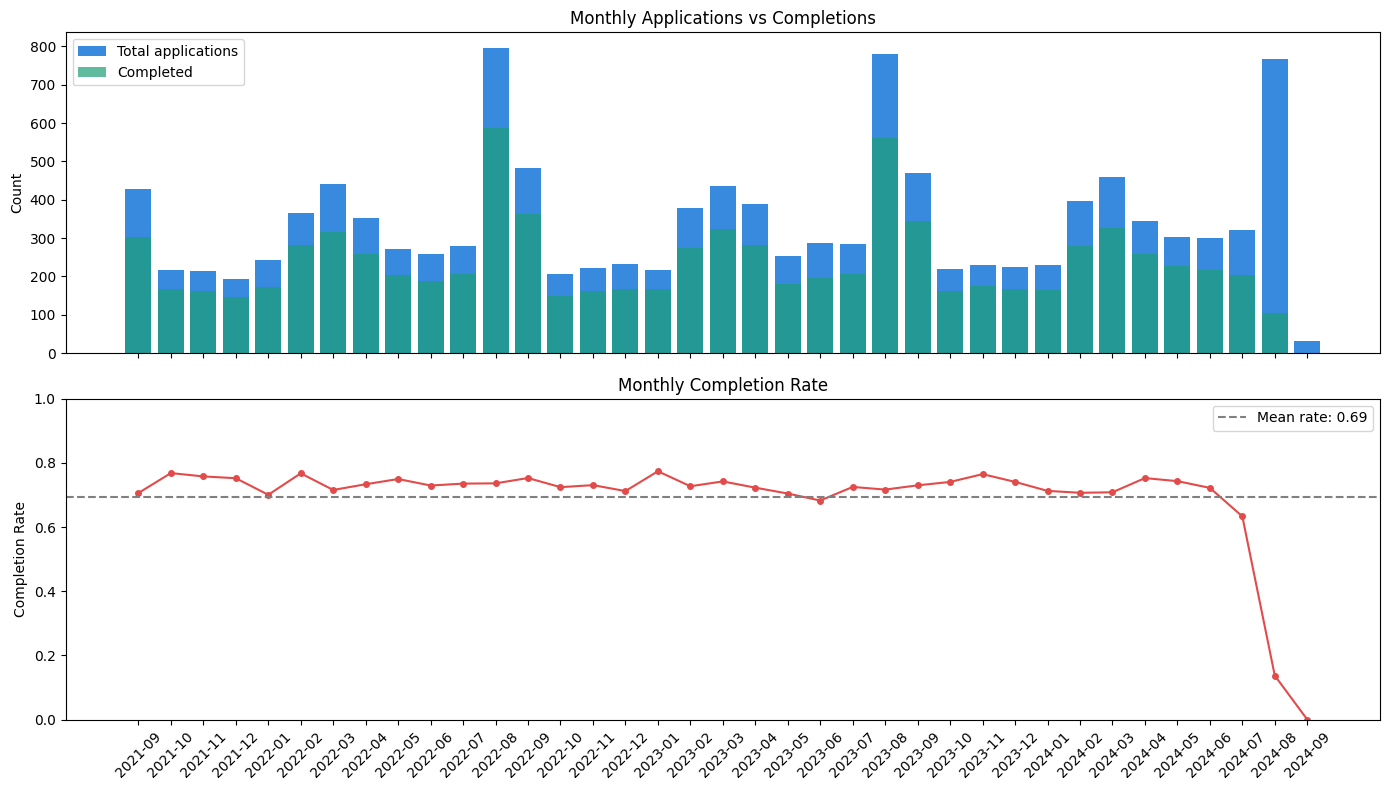

In [10]:
#EDA: Monthly trend of applications and completion rate
base_data['Approval_YearMonth'] = base_data['Approval_Date'].dt.to_period('M').astype(str)

monthly_detail = base_data.groupby('Approval_YearMonth').agg(
    Total=('Complete', 'count'),
    Completed=('Complete', 'sum')
).reset_index()
monthly_detail['Rate'] = monthly_detail['Completed'] / monthly_detail['Total']
monthly_detail = monthly_detail.sort_values('Approval_YearMonth')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top: Count
axes[0].bar(monthly_detail['Approval_YearMonth'], monthly_detail['Total'], 
            color='#378ADD', label='Total applications')
axes[0].bar(monthly_detail['Approval_YearMonth'], monthly_detail['Completed'], 
            color='#1D9E75', label='Completed', alpha=0.7)
axes[0].set_ylabel('Count')
axes[0].set_title('Monthly Applications vs Completions')
axes[0].legend()

# Bottom: Rate
axes[1].plot(monthly_detail['Approval_YearMonth'], monthly_detail['Rate'], 
             color='#E24B4A', marker='o', markersize=4)
axes[1].axhline(monthly_detail['Rate'].mean(), color='gray', linestyle='--', 
                label=f"Mean rate: {monthly_detail['Rate'].mean():.2f}")
axes[1].set_ylabel('Completion Rate')
axes[1].set_title('Monthly Completion Rate')
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(IMG_DIR / 'monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
#remove the last three monthes (Outlier)
last_3_months = base_data['Approval_YearMonth'].sort_values().unique()[-3:]
filtered_data = base_data[~base_data['Approval_YearMonth'].isin(last_3_months)].copy()

In [12]:
#remove invalid Time_To_Complete values
print('Negative durations removed:', (filtered_data['Time_To_Complete'] < 0).sum())
filtered_data = filtered_data[
    filtered_data['Time_To_Complete'].isna() |
    (filtered_data['Time_To_Complete'] >= 0)
].copy()

Negative durations removed: 207


In [13]:
print(filtered_data.columns.tolist())
print(filtered_data.shape)

['Approval_Date', 'Loan', 'Valuation', 'Country', 'Origin', 'Joint', 'App1_Age', 'App2_Age', 'App1_G', 'App2_G', 'App1_Income', 'App2_Income', 'Property_Type', 'Area', 'Property_Age', 'Advance_Date', 'Country_cat', 'Origin_cat', 'Property_Type_cat', 'Area_cat', 'Complete', 'Time_To_Complete', 'Approval_YearMonth']
(11207, 23)


## 2. Train / Test Split
A **chronological split** is used: applications approved before 1 Jan 2024 train the models, and later applications test them. This mirrors real use (predicting future applications) and avoids leaking future information into training.

In [14]:
#train:test about 80:20
split_date = pd.Timestamp('2024-01-01')
end_date   = pd.Timestamp('2024-06-30')

train = filtered_data[filtered_data['Approval_Date'] < split_date].copy()
test  = filtered_data[(filtered_data['Approval_Date'] >= split_date) & 
                      (filtered_data['Approval_Date'] <= end_date)].copy()

print(f"Train: {len(train)}")
print(f"Test:  {len(test)}")

Train: 9213
Test:  1994


In [15]:
print(train['Complete'].value_counts(dropna=False))
print(test['Complete'].value_counts(dropna=False))

Complete
1    6702
0    2511
Name: count, dtype: int64
Complete
1    1432
0     562
Name: count, dtype: int64


### 2.1 Missing values
Imputation values are learned from the training set only and then applied to the test set. Missing second-applicant income is set to 0, because it means there is no second applicant.

In [16]:
filtered_data.info()

<class 'pandas.DataFrame'>
Index: 11207 entries, 0 to 11413
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Approval_Date       11207 non-null  datetime64[us]
 1   Loan                11207 non-null  float64       
 2   Valuation           11207 non-null  float64       
 3   Country             10112 non-null  float64       
 4   Origin              10059 non-null  float64       
 5   Joint               11207 non-null  int64         
 6   App1_Age            11207 non-null  float64       
 7   App2_Age            4525 non-null   float64       
 8   App1_G              11207 non-null  int64         
 9   App2_G              4525 non-null   float64       
 10  App1_Income         11207 non-null  float64       
 11  App2_Income         4525 non-null   float64       
 12  Property_Type       10109 non-null  float64       
 13  Area                10139 non-null  float64       
 14  Proper

In [17]:
#Train
#Numeric
train['Property_Age'] = train['Property_Age'].fillna(train['Property_Age'].median())
train['App2_Income_filled'] = train['App2_Income'].fillna(0)

#Category
train['Country_cat'] = train['Country_cat'].fillna(train['Country_cat'].mode()[0])
train['Origin_cat'] = train['Origin_cat'].fillna(train['Origin_cat'].mode()[0])
train['Property_Type_cat'] = train['Property_Type_cat'].fillna(train['Property_Type_cat'].mode()[0])
train['Area_cat'] = train['Area_cat'].fillna(train['Area_cat'].mode()[0])

#Test
test['Property_Age'] = test['Property_Age'].fillna(train['Property_Age'].median())
test['App2_Income_filled'] = test['App2_Income'].fillna(0)

test['Country_cat'] = test['Country_cat'].fillna(train['Country_cat'].mode()[0])
test['Origin_cat'] = test['Origin_cat'].fillna(train['Origin_cat'].mode()[0])
test['Property_Type_cat'] = test['Property_Type_cat'].fillna(train['Property_Type_cat'].mode()[0])
test['Area_cat'] = test['Area_cat'].fillna(train['Area_cat'].mode()[0])

In [18]:
train.info()

<class 'pandas.DataFrame'>
Index: 9213 entries, 0 to 9380
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Approval_Date       9213 non-null   datetime64[us]
 1   Loan                9213 non-null   float64       
 2   Valuation           9213 non-null   float64       
 3   Country             8328 non-null   float64       
 4   Origin              8291 non-null   float64       
 5   Joint               9213 non-null   int64         
 6   App1_Age            9213 non-null   float64       
 7   App2_Age            3732 non-null   float64       
 8   App1_G              9213 non-null   int64         
 9   App2_G              3732 non-null   float64       
 10  App1_Income         9213 non-null   float64       
 11  App2_Income         3732 non-null   float64       
 12  Property_Type       8283 non-null   float64       
 13  Area                8325 non-null   float64       
 14  Property

In [19]:
test.info()

<class 'pandas.DataFrame'>
Index: 1994 entries, 9381 to 11413
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Approval_Date       1994 non-null   datetime64[us]
 1   Loan                1994 non-null   float64       
 2   Valuation           1994 non-null   float64       
 3   Country             1784 non-null   float64       
 4   Origin              1768 non-null   float64       
 5   Joint               1994 non-null   int64         
 6   App1_Age            1994 non-null   float64       
 7   App2_Age            793 non-null    float64       
 8   App1_G              1994 non-null   int64         
 9   App2_G              793 non-null    float64       
 10  App1_Income         1994 non-null   float64       
 11  App2_Income         793 non-null    float64       
 12  Property_Type       1826 non-null   float64       
 13  Area                1814 non-null   float64       
 14  Prop

## 3. Feature Engineering
Business-driven features: **leverage** (LTV, high-LTV flag), **affordability** (total income, income multiplier), their **interaction**, **timing** (approval month/quarter, average monthly delay from training data only), **log transforms** for skewed amounts, and a **new-build** flag.

In [20]:
#New feature: LTV
train['LTV'] = train['Loan'] / train['Valuation']
test['LTV']  = test['Loan']  / test['Valuation']

train['High_LTV_Flag'] = (train['LTV'] > 0.85).astype(int)
test['High_LTV_Flag'] = (test['LTV'] > 0.85).astype(int)


In [21]:
#New feature: Total_Income and Income_Multiplier

train['Total_Income'] = (
    train['App1_Income'] +
    train['App2_Income_filled']
)

test['Total_Income'] = (
    test['App1_Income'] +
    test['App2_Income_filled']
)


train['Income_Multiplier'] = np.where(
    train['Total_Income'] > 0,
    train['Loan'] / train['Total_Income'],
    np.nan
)
test['Income_Multiplier'] = np.where(
    test['Total_Income'] > 0,
    test['Loan'] / test['Total_Income'],
    np.nan
)

In [22]:
#New feature: LTV x Income_Multiplier
train['LTV_x_Multiplier'] = train['LTV'] * train['Income_Multiplier']
test['LTV_x_Multiplier'] = test['LTV'] * test['Income_Multiplier']

In [23]:
#Seasonal feature
train['Approval_Month'] = train['Approval_Date'].dt.month
test['Approval_Month'] = test['Approval_Date'].dt.month
train['Approval_Quarter'] = train['Approval_Date'].dt.quarter
test['Approval_Quarter'] = test['Approval_Date'].dt.quarter

monthly_delay = train.groupby('Approval_YearMonth')['Time_To_Complete'].mean()
train['Monthly_Avg_Delay'] = train['Approval_YearMonth'].map(monthly_delay)
# For test: map using train-computed values only
test['Monthly_Avg_Delay'] = test['Approval_YearMonth'].map(monthly_delay).fillna(monthly_delay.mean())

In [24]:
#Log
train['log_Loan'] = np.log1p(train['Loan'])
test['log_Loan'] = np.log1p(test['Loan'])

train['log_Valuation'] = np.log1p(train['Valuation'])
test['log_Valuation'] = np.log1p(test['Valuation'])

train['log_Total_Income'] = np.log1p(train['Total_Income'])
test['log_Total_Income'] = np.log1p(test['Total_Income'])

In [25]:
#New feature: Is_New_Build
train['Is_New_Build'] = (train['Property_Age'] == 0).astype(int)
test['Is_New_Build'] = (test['Property_Age'] == 0).astype(int)

### 3.1 Correlation heatmap
Used to check which variables relate to each target and to spot highly correlated features before model selection.

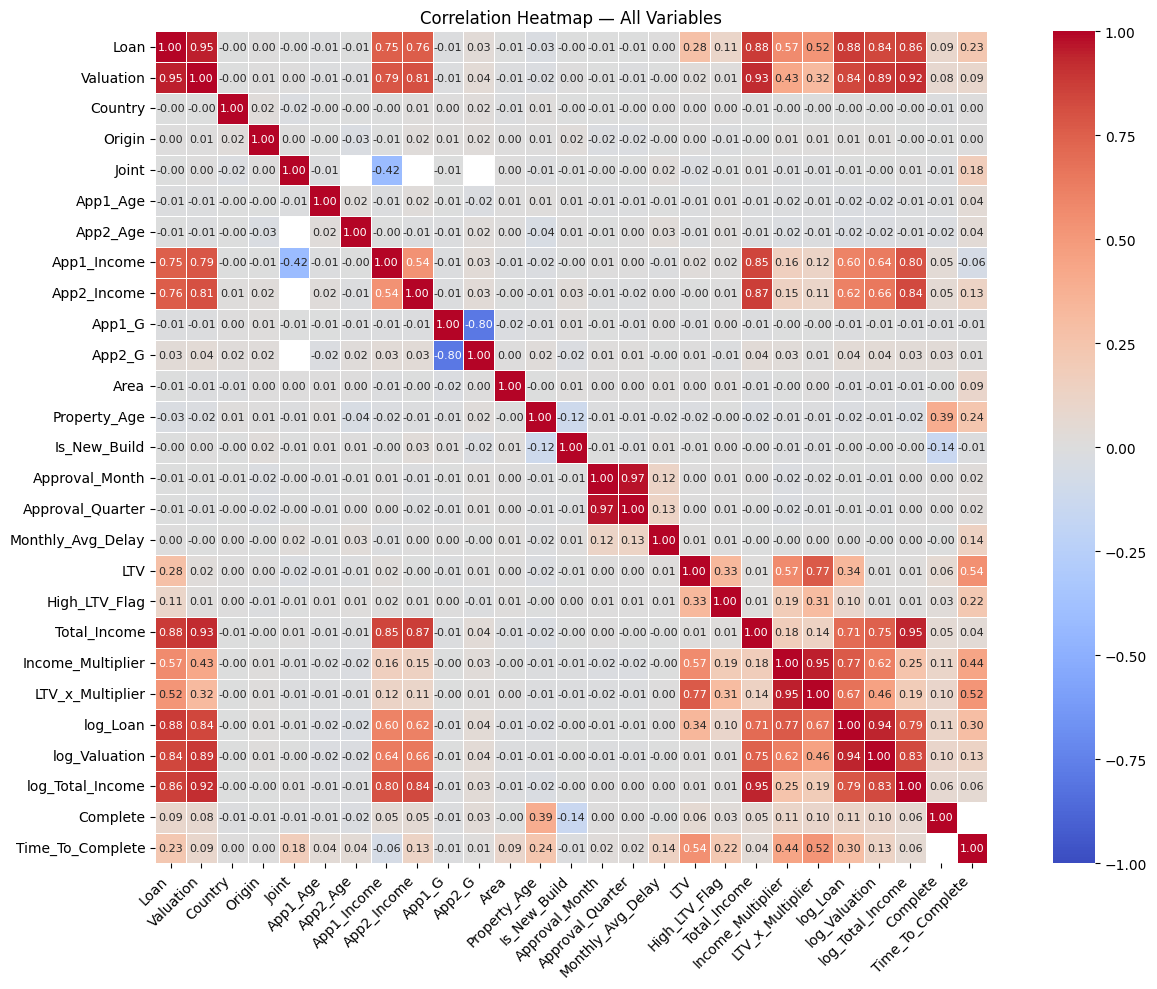

In [26]:
heatmap_cols = [
    'Loan', 'Valuation', 'Country', 'Origin', 'Joint',
    'App1_Age', 'App2_Age', 'App1_Income', 'App2_Income', 'App1_G', 'App2_G',
    'Area', 'Property_Age', 'Is_New_Build',
    'Approval_Month', 'Approval_Quarter', 'Monthly_Avg_Delay', 
    'LTV', 'High_LTV_Flag', 'Total_Income', 'Income_Multiplier', 'LTV_x_Multiplier',
    'log_Loan', 'log_Valuation', 'log_Total_Income',
    'Complete', 'Time_To_Complete'
]

corr_matrix = train[heatmap_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 8}
)
plt.title('Correlation Heatmap — All Variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 One-hot encoding
Categorical variables are one-hot encoded. The test set is aligned to the training columns so both have the same features.

In [27]:
country_mode = train['Country_cat'].mode()[0]
origin_mode = train['Origin_cat'].mode()[0]
property_type_mode = train['Property_Type_cat'].mode()[0]
area_mode = train['Area_cat'].mode()[0]
property_age_median = train['Property_Age'].median()

In [28]:
cat_cols = ['Country_cat', 'Origin_cat', 'Property_Type_cat', 'Area_cat']

train = pd.get_dummies(train, columns=cat_cols, drop_first=True)
test = pd.get_dummies(test, columns=cat_cols, drop_first=True)

test = test.reindex(columns=train.columns, fill_value=0)

## 4. Completion Probability Models
**Business goal:** flag applications likely to fall through, so the business can act early. Recall on *non-completed* cases is therefore prioritised over headline accuracy.

### 4.1 Lasso logistic regression
L1 regularisation (C chosen by 5-fold cross-validation on ROC AUC) removes weak predictors and keeps the model interpretable. The decision threshold is raised to 0.55 to reduce over-optimistic completion predictions.

Best C (1/λ): 0.0886
=== Correlation-Informed Lasso Results ===
Accuracy : 0.6489
ROC AUC  : 0.7905
              precision    recall  f1-score   support

           0       0.43      0.80      0.56       562
           1       0.88      0.59      0.71      1432

    accuracy                           0.65      1994
   macro avg       0.66      0.69      0.63      1994
weighted avg       0.75      0.65      0.67      1994



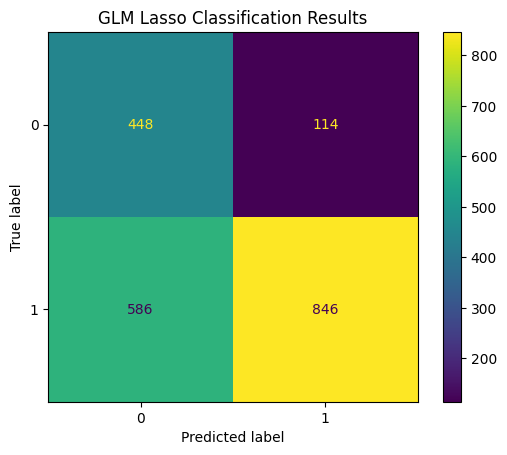


=== Lasso Variable Selection ===
Variables kept   : 11
Variables zeroed : 7

Kept variables:
Property_Age           1.692459
log_Loan               0.193500
Income_Multiplier      0.128179
Property_Type_cat_3    0.073427
LTV                    0.031423
Approval_Quarter       0.011974
Monthly_Avg_Delay      0.008712
Approval_Month         0.007020
App2_Income_filled    -0.001595
App1_Age              -0.032990
Is_New_Build          -0.690315
dtype: float64


In [29]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

features_glm = [
    'Joint', 'App1_Age', 'App1_Income',
    'App2_Income_filled', 'Property_Age','Is_New_Build',
    'Approval_Quarter', 'Monthly_Avg_Delay', 
    'LTV', 'Income_Multiplier', 'Approval_Month',
    'log_Loan', 'log_Valuation', 'log_Total_Income','LTV_x_Multiplier',
    'Property_Type_cat_1', 'Property_Type_cat_2', 'Property_Type_cat_3'
    ]

X_train_glm = train[features_glm].copy()
X_test_glm  = test[features_glm].copy()
y_train_glm = train['Complete']
y_test_glm  = test['Complete']

# Scale numeric features
cols_to_scale = [
    'App1_Age', 'App1_Income', 'App2_Income_filled',
    'Property_Age', 'Monthly_Avg_Delay',
    'LTV', 'Income_Multiplier',
    'log_Loan', 'log_Valuation', 'log_Total_Income', 'LTV_x_Multiplier'
]
scaler = StandardScaler()
X_train_glm[cols_to_scale] = scaler.fit_transform(X_train_glm[cols_to_scale])
X_test_glm[cols_to_scale]  = scaler.transform(X_test_glm[cols_to_scale])

# Fit GLM + Lasso with CV to find best C
lasso_cv = LogisticRegressionCV(
    penalty='l1',
    solver='liblinear',
    Cs=20,              
    cv=5,
    scoring='roc_auc',
    random_state=42,
    max_iter=1000,
    class_weight='balanced'
)
lasso_cv.fit(X_train_glm, y_train_glm)
print(f"Best C (1/λ): {lasso_cv.C_[0]:.4f}")

#Evaluation
y_prob = lasso_cv.predict_proba(X_test_glm)[:, 1]
y_pred = (y_prob >= 0.55).astype(int)

print("=== Correlation-Informed Lasso Results ===")
print(f"Accuracy : {accuracy_score(y_test_glm, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test_glm, y_prob):.4f}")
print(classification_report(y_test_glm, y_pred))

cm = confusion_matrix(y_test_glm, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title('GLM Lasso Classification Results')
plt.savefig(IMG_DIR / 'lasso_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

coef_df = pd.Series(lasso_cv.coef_[0], index=X_train_glm.columns)
kept   = coef_df[coef_df != 0].sort_values(ascending=False)
zeroed = coef_df[coef_df == 0]

print(f"\n=== Lasso Variable Selection ===")
print(f"Variables kept   : {len(kept)}")
print(f"Variables zeroed : {len(zeroed)}")
print(f"\nKept variables:")
print(kept)


### 4.2 Random Forest (non-linear benchmark)
Uses the variables kept by Lasso, to test whether non-linear patterns add predictive value.

=== Random Forest (Lasso-selected variables) ===
Accuracy : 0.6810
ROC AUC  : 0.7878
              precision    recall  f1-score   support

           0       0.46      0.71      0.56       562
           1       0.86      0.67      0.75      1432

    accuracy                           0.68      1994
   macro avg       0.66      0.69      0.65      1994
weighted avg       0.74      0.68      0.70      1994



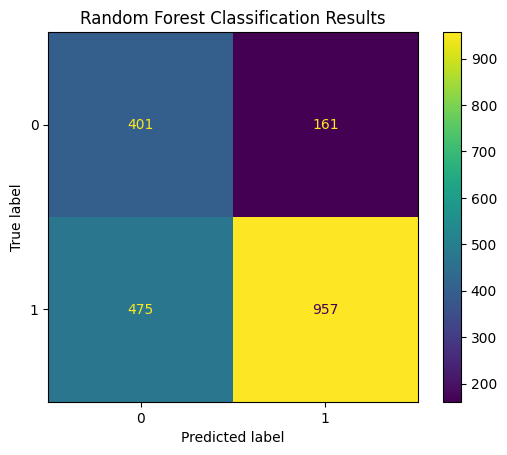


Feature Importance:
Property_Age           0.662588
log_Loan               0.066188
Income_Multiplier      0.062299
LTV                    0.052958
Is_New_Build           0.038768
App1_Age               0.035897
App2_Income_filled     0.028904
Monthly_Avg_Delay      0.024278
Approval_Month         0.015948
Approval_Quarter       0.007355
Property_Type_cat_3    0.004817
dtype: float64


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

#Use variables selected by Lasso
lasso_kept = [
    'Property_Age',
    'Income_Multiplier',
    'log_Loan',
    'LTV',
    'Is_New_Build',
    'Property_Type_cat_3',
    'Approval_Quarter',
    'Monthly_Avg_Delay',
    'Approval_Month',
    'App2_Income_filled',
    'App1_Age',
]

X_train_rf = train[lasso_kept].copy()
X_test_rf  = test[lasso_kept].copy()
y_train_rf = train['Complete']
y_test_rf  = test['Complete']

#Fit Random Forest
Rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)
Rf_model.fit(X_train_rf, y_train_rf)

#Evaluate
y_prob_rf = Rf_model.predict_proba(X_test_rf)[:, 1]
y_pred_rf = (y_prob_rf >= 0.75).astype(int)

print("=== Random Forest (Lasso-selected variables) ===")
print(f"Accuracy : {accuracy_score(y_test_rf, y_pred_rf):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test_rf, y_prob_rf):.4f}")
print(classification_report(y_test_rf, y_pred_rf))

# Confusion matrix
cm_rf = confusion_matrix(y_test_rf, y_pred_rf)
ConfusionMatrixDisplay(confusion_matrix=cm_rf).plot()
plt.title('Random Forest Classification Results')
plt.savefig(IMG_DIR / 'rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Feature importance
importance = pd.Series(
    Rf_model.feature_importances_,
    index=X_train_rf.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

## 5. Time-to-Completion Models
Trained on **completed applications only**, since completion time is only observed for cases that completed.

### 5.1 Linear regression (baseline)

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import numpy as np

features_ols = [
    'Joint',
    'App1_Income',
    'App2_Income_filled',
    'Property_Age',
    'LTV',
    'LTV_x_Multiplier',
    'Income_Multiplier',
    'log_Loan',      
    'Is_New_Build',       
    'Monthly_Avg_Delay', 
    
    ]

train_time = train[train['Complete'] == 1].copy()
test_time = test[test['Complete'] == 1].copy()

X_train_ols = train_time[features_ols].copy()
X_test_ols = test_time[features_ols].copy()
y_train_ols = train_time['Time_To_Complete']
y_test_ols = test_time['Time_To_Complete']

#Fit: OLS model
ols_model = LinearRegression()
ols_model.fit(X_train_ols, y_train_ols)

#Evaluate OLS
y_pred_ols = ols_model.predict(X_test_ols)

print("=== Linear Regression ===")
print(f"R²   : {r2_score(y_test_ols, y_pred_ols):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_ols, y_pred_ols)):.2f} days")
print(f"MAE  : {mean_absolute_error(y_test_ols, y_pred_ols):.2f} days")

=== Linear Regression ===
R²   : 0.4271
RMSE : 10.64 days
MAE  : 8.43 days


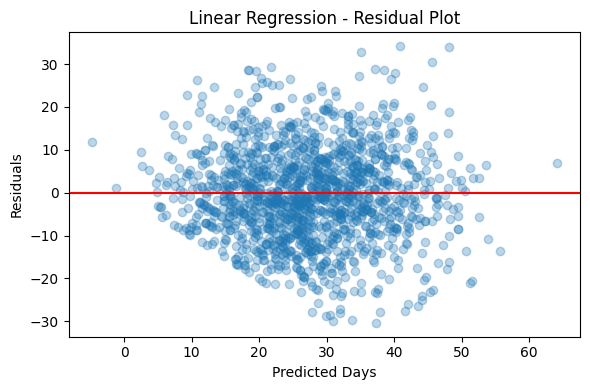

Negative predictions: 2 out of 1432 (0.1%)


In [32]:
import matplotlib.pyplot as plt
import numpy as np

residuals_ols = y_test_ols - y_pred_ols

plt.figure(figsize=(6, 4))
plt.scatter(y_pred_ols, residuals_ols, alpha=0.3)
plt.axhline(0, color='red')
plt.xlabel('Predicted Days')
plt.ylabel('Residuals')
plt.title('Linear Regression - Residual Plot')
plt.tight_layout()
plt.show()

neg_preds = np.sum(y_pred_ols < 0)
print(f"Negative predictions: {neg_preds} out of {len(y_pred_ols)} ({neg_preds/len(y_pred_ols)*100:.1f}%)")

### 5.2 XGBoost regression
Captures interactions (e.g. high LTV behaving differently for joint vs single applicants). The training data is split 80:20 chronologically for validation; final performance is reported on the test set.

In [33]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

features_xgb = [
    
    'Joint',
    'App1_Income',
    'App2_Income_filled',
    'Property_Age',
    'LTV',
    'LTV_x_Multiplier',
    'Income_Multiplier',
    'log_Loan',       
    'Is_New_Build',       
    'Monthly_Avg_Delay',
    'High_LTV_Flag',
    'Approval_Month',
    'Approval_Quarter'
    

    ]

train_time = train[train['Complete'] == 1].copy()
test_time = test[test['Complete'] == 1].copy()

#Validation split (80:20)
split_idx = int(len(train_time) * 0.8)

train_sub = train_time.iloc[:split_idx].copy()
valid_sub = train_time.iloc[split_idx:].copy()

X_train_xgb = train_sub[features_xgb].copy()
y_train_xgb = train_sub['Time_To_Complete']
X_valid_xgb = valid_sub[features_xgb].copy()
y_valid_xgb = valid_sub['Time_To_Complete']
X_test_xgb = test_time[features_xgb].copy()
y_test_xgb = test_time['Time_To_Complete']

#Fit: XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train_xgb, y_train_xgb)

# Predict(Validation)
y_pred_valid = xgb_model.predict(X_valid_xgb)

# Evaluate on validation set (used for tuning; final results are on the test set below)
print("=== XGBoost Regression (Validation) ===")
print(f"R²   : {r2_score(y_valid_xgb, y_pred_valid):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_valid_xgb, y_pred_valid)):.2f} days")
print(f"MAE  : {mean_absolute_error(y_valid_xgb, y_pred_valid):.2f} days")

=== XGBoost Regression (Validation) ===
R²   : 0.4813
RMSE : 10.17 days
MAE  : 8.08 days


In [34]:
#Predict(Test)
y_pred_xgb = xgb_model.predict(X_test_xgb)

print("\n=== Test Performance ===")
print(f"R²   : {r2_score(y_test_xgb, y_pred_xgb):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_xgb, y_pred_xgb)):.2f} days")
print(f"MAE  : {mean_absolute_error(y_test_xgb, y_pred_xgb):.2f} days")


=== Test Performance ===
R²   : 0.4621
RMSE : 10.31 days
MAE  : 8.18 days


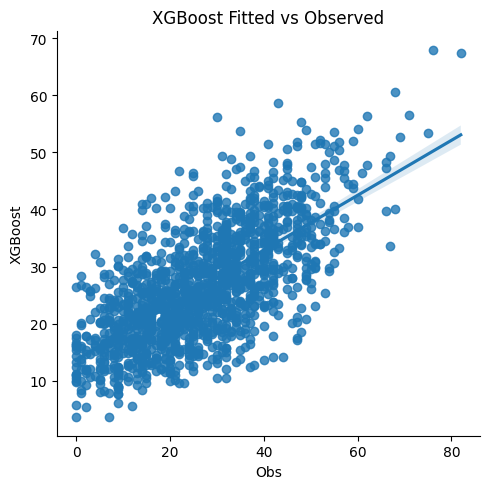

In [35]:
# Plot fitted vs observed
xgb_fv_obs = pd.DataFrame([y_pred_xgb, y_test_xgb]).set_axis(['XGBoost', 'Obs'], axis=0).T

g = sns.lmplot(
    data=xgb_fv_obs,
    x='Obs',
    y='XGBoost',
    height=5
)

plt.title('XGBoost Fitted vs Observed')
plt.tight_layout()
plt.savefig(IMG_DIR / 'xgb_fitted_vs_observed.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Two-Month Cashflow Forecast (Bootstrap)
Combines both models to forecast how much will be advanced from the **open pipeline** in the next 61 days. In each of 500 runs, the models are retrained on resampled data; each open case is simulated as completing (Lasso probability) and timed (XGBoost). Loans completing within the window are summed, producing a distribution rather than a single estimate.

=== Simulated Cashflow in Next Two Months ===
Mean   : 87,468,222
Median : 87,357,500
5%     : 82,559,700
95%    : 92,484,700


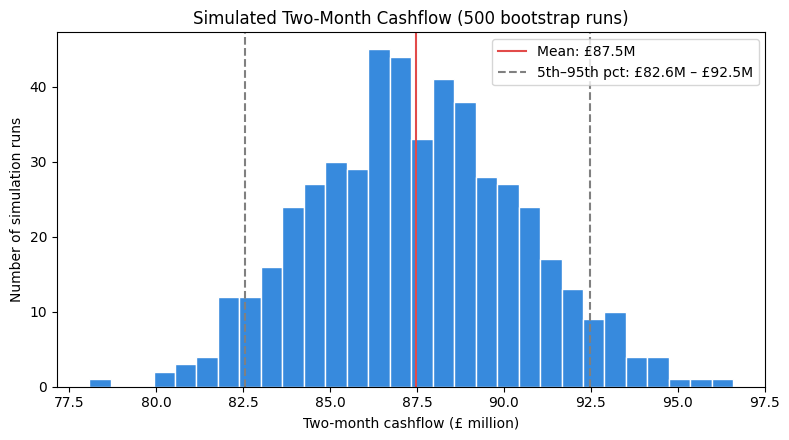

In [36]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBRegressor

# The cases are still in pipeline (not completed yet)
pipeline_end = base_data[base_data['Approval_YearMonth'].isin(last_3_months)].copy()
pipeline_open = pipeline_end[pipeline_end['Complete'] == 0].copy()

# Address missing values
# Train
pipeline_open['Property_Age'] = pipeline_open['Property_Age'].fillna(property_age_median)
pipeline_open['App2_Income_filled'] = pipeline_open['App2_Income'].fillna(0)

pipeline_open['Country_cat'] = pipeline_open['Country_cat'].fillna(country_mode)
pipeline_open['Origin_cat'] = pipeline_open['Origin_cat'].fillna(origin_mode)
pipeline_open['Property_Type_cat'] = pipeline_open['Property_Type_cat'].fillna(property_type_mode)
pipeline_open['Area_cat'] = pipeline_open['Area_cat'].fillna(area_mode)

# Feature Engineering
# Total Income
pipeline_open['Total_Income'] = (
    pipeline_open['App1_Income'] + pipeline_open['App2_Income_filled']
)

# LTV
pipeline_open['LTV'] = pipeline_open['Loan'] / pipeline_open['Valuation']
# Income Multiplier
pipeline_open['Income_Multiplier'] = np.where(
    pipeline_open['Total_Income'] > 0,
    pipeline_open['Loan'] / pipeline_open['Total_Income'],
    np.nan
)
# LTV x Income Multiplier
pipeline_open['LTV_x_Multiplier'] = pipeline_open['LTV'] * pipeline_open['Income_Multiplier']

# Seasonal features
pipeline_open['Approval_Date'] = pd.to_datetime(pipeline_open['Approval_Date'])

pipeline_open['Approval_Month'] = pipeline_open['Approval_Date'].dt.month
pipeline_open['Approval_Quarter'] = pipeline_open['Approval_Date'].dt.quarter

# Monthly Avg Delay
pipeline_open['Monthly_Avg_Delay'] = pipeline_open['Approval_YearMonth'].map(monthly_delay).fillna(monthly_delay.mean())

# Log transformations
pipeline_open['log_Loan'] = np.log1p(pipeline_open['Loan'])
pipeline_open['log_Valuation'] = np.log1p(pipeline_open['Valuation'])
pipeline_open['log_Total_Income'] = np.log1p(pipeline_open['Total_Income'])

# Is_New_Build
pipeline_open['Is_New_Build'] = (pipeline_open['Property_Age'] == 0).astype(int)

# One-hot encoding for categorical variables
cat_cols = ['Country_cat', 'Origin_cat', 'Property_Type_cat', 'Area_cat']
pipeline_open = pd.get_dummies(pipeline_open, columns=cat_cols, drop_first=True)

pipeline_open = pipeline_open.reindex(columns=train.columns, fill_value=0)

# Bootstrap
np.random.seed(42)  # fixed seed so the results are reproducible
n_bootstraps = 500
two_months_days = 61
cashflow_samples = []
train_all = train.copy()

X_train_complete = train_all[features_glm].copy()
# Apply the scaler fitted earlier: C=0.0886 was selected on standardised features
X_train_complete[cols_to_scale] = scaler.transform(X_train_complete[cols_to_scale])
y_train_complete = train_all['Complete']

train_time_all = train_all[train_all['Complete'] == 1]
X_train_complete_time = train_time_all[features_xgb]
y_train_complete_time = train_time_all['Time_To_Complete']

X_open = pipeline_open[features_glm].copy()
X_open[cols_to_scale] = scaler.transform(X_open[cols_to_scale])
X_open_time = pipeline_open[features_xgb].copy()
loans = pipeline_open['Loan'].values

cashflow_samples = []

for i in range(n_bootstraps):
    # Resample with replacement
    sample_idx_complete = np.random.choice(len(X_train_complete), size=len(X_train_complete), replace=True)
    sample_idx_complete_time = np.random.choice(len(X_train_complete_time), size=len(X_train_complete_time), replace=True)

    # Fit Lasso on the bootstrap sample
    lasso_sample = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=0.0886,
    max_iter=1000,
    class_weight='balanced',
    random_state=i
    )
    lasso_sample.fit(
    X_train_complete.iloc[sample_idx_complete],
    y_train_complete.iloc[sample_idx_complete]
    )

    # Predict probabilities for open cases
    p_complete = lasso_sample.predict_proba(X_open)[:, 1]

    # Fit XGBoost on the complete time data
    xgb_time = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=i
    )
    xgb_time.fit(
    X_train_complete_time.iloc[sample_idx_complete_time],
    y_train_complete_time.iloc[sample_idx_complete_time]
    )
    
    # Predict time to complete for open cases
    days_pred = xgb_time.predict(X_open_time)
   
    # Simulate whether each open case will complete
    completed = np.random.binomial(1, p_complete)

    # Completed within two months
    in_window = (completed == 1) & (days_pred <= two_months_days)

    # Total cashflow in this bootstrap sample
    total_cashflow = np.sum(loans[in_window])
    cashflow_samples.append(total_cashflow)

cashflow_samples = np.array(cashflow_samples)

print("=== Simulated Cashflow in Next Two Months ===")
print(f"Mean   : {cashflow_samples.mean():,.0f}")
print(f"Median : {np.median(cashflow_samples):,.0f}")
print(f"5%     : {np.percentile(cashflow_samples, 5):,.0f}")
print(f"95%    : {np.percentile(cashflow_samples, 95):,.0f}")

# Distribution of simulated cashflow
p5, p95 = np.percentile(cashflow_samples, [5, 95])
plt.figure(figsize=(8, 4.5))
plt.hist(cashflow_samples / 1e6, bins=30, color='#378ADD', edgecolor='white')
plt.axvline(cashflow_samples.mean() / 1e6, color='#E24B4A', linestyle='-', label=f"Mean: £{cashflow_samples.mean()/1e6:.1f}M")
plt.axvline(p5 / 1e6, color='gray', linestyle='--', label=f"5th–95th pct: £{p5/1e6:.1f}M – £{p95/1e6:.1f}M")
plt.axvline(p95 / 1e6, color='gray', linestyle='--')
plt.xlabel('Two-month cashflow (£ million)')
plt.ylabel('Number of simulation runs')
plt.title('Simulated Two-Month Cashflow (500 bootstrap runs)')
plt.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / 'cashflow_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Conclusion
- **Completion risk:** Lasso and Random Forest perform similarly (ROC AUC ≈ 0.79). Lasso is preferred because it is simpler to explain and catches more non-completing cases.
- **Completion time:** XGBoost improves only slightly on linear regression, which points to missing process-level data (legal status, chain length) rather than a modelling limitation.
- **Cashflow:** the bootstrap produces an expected two-month cashflow with a 5th–95th percentile range that can be used for funding and liquidity planning.
